# Módulo 7 — Cointegração

## Seção 1 — Regressão espúria: por que duas séries com raiz unitária podem parecer relacionadas?

**Estado editorial:** seção didática para revisão científica. **Pré-requisitos:** processos estocásticos, passeio aleatório e integração $I(1)$ (Módulos 1 e 3); mínimos quadrados, testes de hipóteses e ACF (Módulos 2 e 4). **Convenção:** $t=1,\ldots,n$ indica instantes igualmente espaçados; $X_t$ e $Y_t$ são processos; letras minúsculas denotam trajetórias observadas.

**Controle das fontes.** O `PLANO_MODULOS_PRIORITARIOS.md` prevê regressão espúria como primeiro tema do Módulo 7. O `mapeamento-conteudos-series-temporais.md`, §6.1, informa que cointegração não foi encontrada nas videoaulas e recomenda Hamilton (1994), caps. 19–20, e Enders (2014) como **leituras complementares a consultar**. O PDF de Morettin e Toloi fornecido está sem camada textual pesquisável; não se confirmou nele uma seção específica de regressão espúria. Por isso, **todas as demonstrações, exemplos e códigos desta seção são complementações didáticas originais**, alinhadas aos temas clássicos de Granger e Newbold (1974) e Phillips (1986), listados como leituras a verificar, **não páginas afirmadas como lidas**.

### Objetivos de aprendizagem

Ao final, você deverá (1) reconhecer uma regressão espúria; (2) distinguir associação amostral de vínculo de equilíbrio; (3) derivar a não estacionariedade do passeio aleatório; (4) compreender por que inferência convencional pode falhar; (5) reproduzir um exemplo numérico e uma experiência de Monte Carlo; (6) avaliar limites da análise sem presumir que correlação signifique causalidade.

### 1. O problema: uma reta convincente entre grandezas desconectadas

Imagine duas variáveis medidas mensalmente, mas geradas por mecanismos completamente separados. Ambas acumulam seus próprios choques ao longo do tempo. É possível que, durante alguns anos, cresçam ou diminuam juntas **por acaso**. Regressar uma contra a outra pode produzir um coeficiente aparentemente importante e um $R^2$ elevado, apesar da ausência de vínculo econômico, físico ou probabilístico entre seus choques.

A expressão **regressão espúria** se refere, aqui, à interpretação enganosa de uma relação de regressão convencional entre séries não estacionárias sem um vínculo de longo prazo adequadamente fundamentado. **Não significa que toda regressão com variáveis $I(1)$ seja inválida**: a Seção 2 mostrará a exceção estrutural da cointegração.

### 2. Retomada matemática: dois passeios aleatórios independentes

Considere, para $t\ge1$,

$$
X_t=X_{t-1}+\varepsilon_t,\qquad
Y_t=Y_{t-1}+\eta_t,\qquad X_0=Y_0=0.
$$

Suponha que $\{\varepsilon_t\}$ e $\{\eta_t\}$ sejam sequências independentes entre si e ao longo do tempo, ambas com média zero e variância $\sigma^2>0$. Por substituição sucessiva:

$$
X_t=\sum_{j=1}^{t}\varepsilon_j,\qquad
Y_t=\sum_{j=1}^{t}\eta_j.
$$

Portanto, para cada processo,

$$
E[X_t]=0,\quad \operatorname{Var}(X_t)=t\sigma^2,
\qquad
\operatorname{Cov}(X_s,X_t)=\sigma^2\min(s,t).
$$

A variância depende do instante; o processo em nível **não** é fracamente estacionário. Em compensação,

$$
\Delta X_t=\varepsilon_t,\qquad\Delta Y_t=\eta_t
$$

são estacionários de segunda ordem (ruídos brancos). Dizemos que $X_t$ e $Y_t$ são $I(1)$ no sentido operacional introduzido no Módulo 3: tornam-se $I(0)$ depois de uma diferença, mas não antes, sob as hipóteses deste exemplo.

**Observação rigorosa:** a independência dos dois passeios implica $\operatorname{Cov}(X_t,Y_s)=0$ para quaisquer $t,s$; contudo, a **covariância teórica** nula não obriga que o coeficiente de regressão estimado a partir de uma única trajetória seja próximo de zero em amostras persistentes.

### 3. A regressão em nível e o que MQO realmente calcula

Mesmo sem relação entre os processos, poderíamos ajustar

$$
Y_t=a+bX_t+u_t,\qquad t=1,\ldots,n.
$$

Com intercepto, os estimadores de mínimos quadrados são

$$
\widehat b=\frac{\sum_{t=1}^{n}(x_t-\overline x)(y_t-\overline y)}{\sum_{t=1}^{n}(x_t-\overline x)^2},\qquad
\widehat a=\overline y-\widehat b\,\overline x.
$$

Esses coeficientes **existem como operações algébricas**, desde que os valores de $x_t$ não sejam todos iguais. O problema está em interpretar os resultados como se os pressupostos de inferência usual com regressoras e erros estacionários adequadamente comportados fossem automaticamente satisfeitos.

De fato, o resíduo observado é

$$
\widehat u_t=y_t-\widehat a-\widehat b x_t.
$$

Se os dados são dois passeios aleatórios independentes, não há razão teórica para esperar uma combinação estacionária dos seus níveis. A reta pode acompanhar visualmente um segmento, mas o resíduo ainda apresenta flutuações persistentes.

### 4. Por que o valor $t$ usual pode ser enganoso?

Um teste convencional da hipótese $H_0:b=0$ costuma usar

$$
t_{\mathrm{usual}}=\frac{\widehat b}{\widehat{\operatorname{se}}(\widehat b)}.
$$

A interpretação pela distribuição $t$ de Student exige hipóteses sobre o erro e o desenho da regressão que **não são transportadas automaticamente** para níveis de processos com raiz unitária. Além disso, as somas $\sum (X_t-\overline X)^2$ e $\sum (X_t-\overline X)(Y_t-\overline Y)$ têm comportamento assintótico diferente daquele da regressão estacionária convencional: oscilações de grande escala não se cancelam da mesma forma que flutuações de memória curta.

Em condições clássicas específicas, estatísticas usuais podem divergir ou convergir a distribuições não padrão sob a ausência de relação verdadeira. A dedução assintótica completa via movimento browniano está fora do escopo desta seção introdutória; **não** apresentaremos uma taxa assintótica universal sem essas hipóteses.

**Consequência:** $p$-valores pequenos e $R^2$ altos podem ocorrer com frequência muito maior que a taxa nominal, mesmo quando os processos foram gerados independentemente. Essa afirmação será investigada em simulação — a simulação ilustra o fenômeno, não substitui sua teoria limite.

### 5. Exemplo manual: MQO também funciona quando não prova relação

Considere duas sequências fictícias de cinco instantes, escolhidas só para conferir a conta:

| $t$ | $x_t$ | $y_t$ |
|---:|---:|---:|
| 1 | 0 | 1 |
| 2 | 1 | 3 |
| 3 | 2 | 2 |
| 4 | 3 | 4 |
| 5 | 4 | 5 |

Temos $\overline x=2$ e $\overline y=3$. As somas centradas são

$$
\sum(x_t-2)^2=10,\qquad\sum(x_t-2)(y_t-3)=9.
$$

Logo,

$$
\widehat b=0{,}9,\qquad\widehat a=3-0{,}9(2)=1{,}2.
$$

**O que isso prova?** Apenas que a reta $\widehat y_t=1{,}2+0{,}9x_t$ minimiza a soma de quadrados para esses cinco pares. Não prova que os dados sejam passeios aleatórios, que estejam cointegrados, que exista causalidade nem que a relação seja preditiva. O exemplo numérico serve para separar **estimação algébrica** de **interpretação estatística**.

### 6. Python — visualizar a armadilha em um caso reproduzível

**Bibliotecas:** NumPy gera inovações e somas acumuladas; Statsmodels ajusta MQO e calcula ADF; Matplotlib permite examinar níveis, diferenças e resíduos. A semente garante reprodutibilidade desta simulação, não generalização de uma trajetória.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

rng = np.random.default_rng(20261121)
n = 350
x = np.cumsum(rng.normal(size=n))
y = np.cumsum(rng.normal(size=n))  # sequência independente de choques

ajuste = sm.OLS(y, sm.add_constant(x)).fit()
residuos = ajuste.resid
print('Intercepto e inclinação:', np.round(ajuste.params, 3))
print('R² em nível:', round(ajuste.rsquared, 3))
print('p-valor t usual da inclinação:', ajuste.pvalues[1])
print('ADF do resíduo (diagnóstico, NÃO teste EG):',
      round(adfuller(residuos, regression='n', autolag='AIC')[0], 3))

fig, axs = plt.subplots(3, 1, figsize=(10, 9))
axs[0].plot(x, label='X: passeio aleatório')
axs[0].plot(y, label='Y: passeio aleatório independente')
axs[0].legend()
axs[0].set_title('Níveis: duas trajetórias sem vínculo gerador')
axs[1].scatter(x, y, s=12, alpha=0.55, label='Pares observados')
ordem = np.argsort(x)
axs[1].plot(x[ordem], ajuste.predict(sm.add_constant(x))[ordem],
            label='Reta MQO')
axs[1].set(xlabel='X', ylabel='Y', title='Regressão em nível')
axs[1].legend()
axs[2].plot(residuos, label='Resíduo estimado')
axs[2].axhline(0, color='gray', lw=0.8)
axs[2].set(xlabel='Tempo', ylabel='Resíduo',
           title='Resíduos: investigar persistência, não presumir I(0)')
for a in axs:
    a.grid(alpha=0.2)
plt.tight_layout()
plt.show()

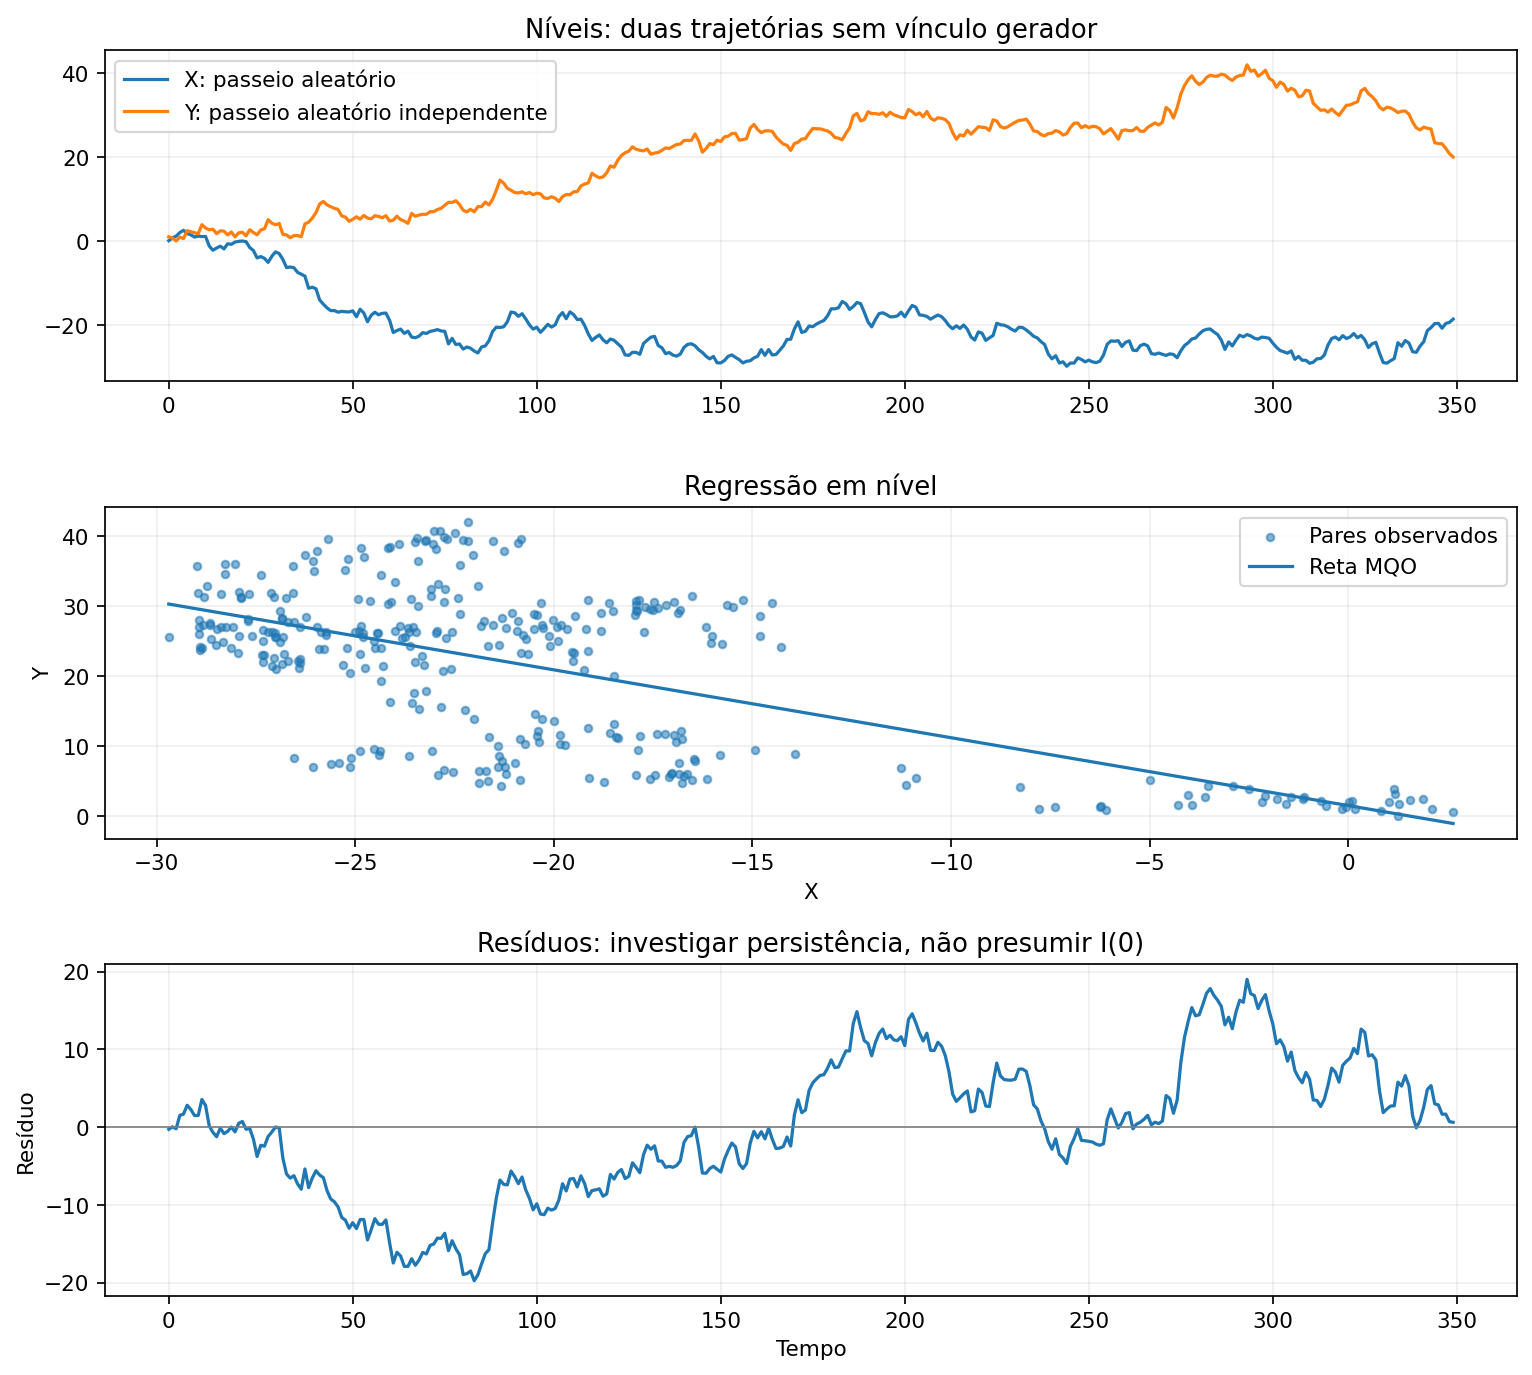

*Figura 7.1 — Dois passeios aleatórios independentes, a reta ajustada por MQO e os resíduos. A aparência da reta não estabelece uma relação de longo prazo. O ADF isolado sobre resíduos gerados pela regressão não usa automaticamente os valores críticos corretos do procedimento de Engle–Granger.*

**Leitura do código:** `np.cumsum` acumula inovações para gerar o passeio; `sm.add_constant` inclui intercepto; `OLS(...).fit()` resolve a regressão; `params`, `rsquared` e `pvalues` são resultados **convencionais** da regressão; `resid` contém os desvios do ajuste. Eles não demonstram validade inferencial sob raízes unitárias.

### 7. Experimento de Monte Carlo: quantas falsas 'descobertas'?

Agora repetimos **muitos** experimentos independentes com $b=0$ no mecanismo gerador, embora cada par de passeios possa produzir um resultado de MQO diferente.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

rng = np.random.default_rng(719)
repeticoes, n = 250, 250
p_convencionais = np.empty(repeticoes)
r2 = np.empty(repeticoes)

for j in range(repeticoes):
    x = np.cumsum(rng.normal(size=n))
    y = np.cumsum(rng.normal(size=n))
    r = sm.OLS(y, sm.add_constant(x)).fit()
    p_convencionais[j] = r.pvalues[1]
    r2[j] = r.rsquared

taxa = np.mean(p_convencionais < 0.05)
print(f'Fração de p-valores usuais < 0,05: {taxa:.3f}')
print(f'R² mediano: {np.median(r2):.3f}')
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(p_convencionais, bins=20)
axs[0].axvline(0.05, ls='--', label='Limiar convencional 5%')
axs[0].set(xlabel='p-valor t usual', ylabel='Número de experimentos')
axs[0].legend()
axs[1].hist(r2, bins=20)
axs[1].set(xlabel='R² em nível', ylabel='Número de experimentos')
plt.tight_layout()
plt.show()

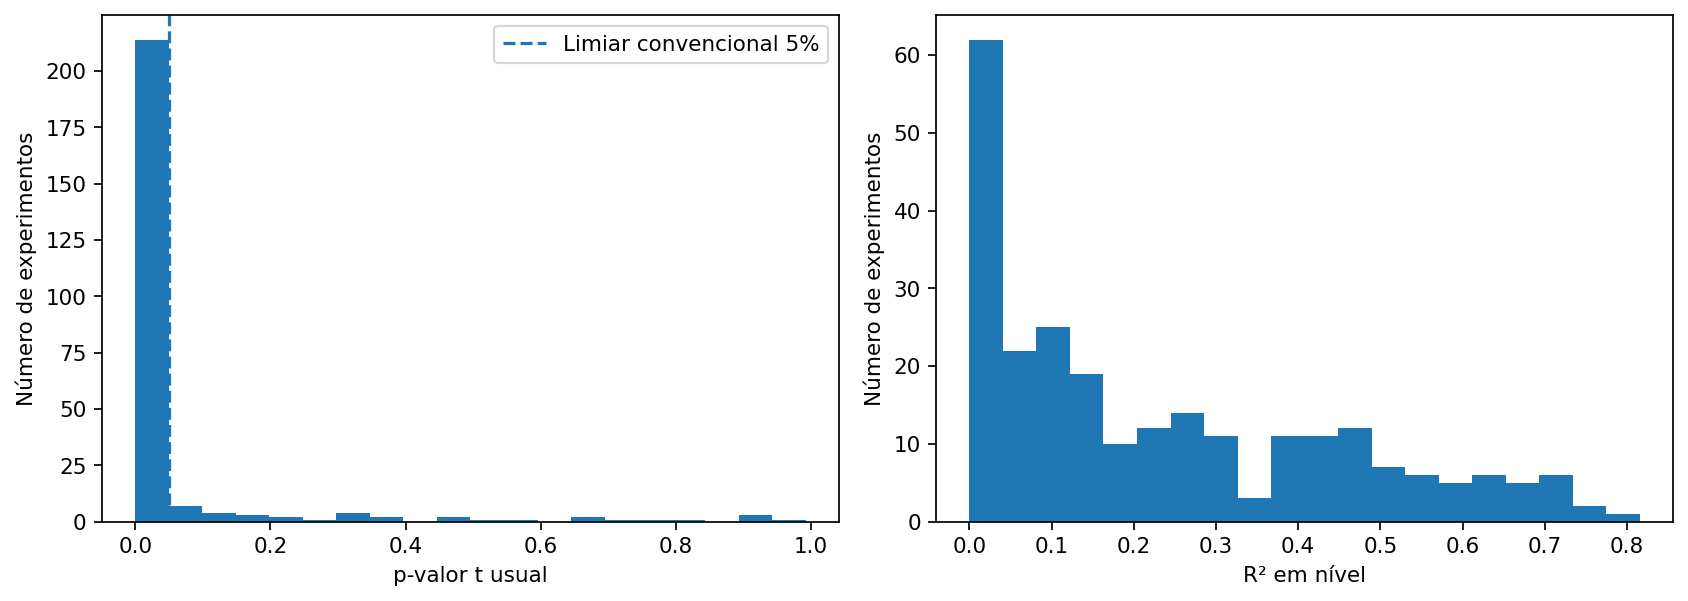

*Figura 7.2 — Distribuição empírica de $p$-valores convencionais e de $R^2$ em 250 pares de passeios aleatórios independentes. A fração de rejeições a 5% é uma característica da simulação e **não** um nível de significância calibrado para esses dados.*

### 8. Como proceder em uma análise científica?

1. **Começar pelo problema e pelas unidades:** por que essas variáveis deveriam estar relacionadas? Observações simultâneas e gráficos parecidos não são explicação substantiva.
2. **Examinar integração e componentes determinísticos:** verificar datas, tendências, sazonalidade, quebras, ADF/KPSS e suas limitações. Não tomar uma decisão exclusivamente pelo gráfico.
3. **Considerar regressão em diferenças quando o interesse for curto prazo:** isso evita regressar níveis integrados sem justificativa, mas pode eliminar informação importante de longo prazo, caso ela exista.
4. **Investigar cointegração quando houver hipótese de equilíbrio:** uma combinação linear estacionária de variáveis $I(1)$ pode justificar o estudo da relação em níveis; o teste requer **valores críticos próprios**, que serão introduzidos em outra seção.
5. **Validar fora da amostra se houver finalidade preditiva:** parâmetros e decisões devem usar apenas os dados disponíveis na origem de cada previsão.

**Limitações:** tendências determinísticas mal especificadas podem produzir outros tipos de associação artificial; quebras estruturais podem imitar ou ocultar integração; séries com sazonalidade estocástica exigem tratamento específico; a independência entre inovações foi imposta apenas para construir o contraexemplo. Regressão espúria não equivale a provar 'ausência de qualquer relação' nos dados reais.

### 9. Exercícios graduais

**Conceitual.** Explique a diferença entre $\operatorname{Cov}(X_t,Y_t)=0$ no processo gerador e a covariância *amostral* calculada em uma única trajetória.

**Demonstração.** Derive $\operatorname{Var}(X_t)=t\sigma^2$ e $\operatorname{Cov}(X_s,X_t)=\sigma^2\min(s,t)$ para o passeio aleatório de inovações independentes.

**Cálculo.** Refaça o exemplo de cinco pares usando a fórmula explícita de MQO; calcule dois resíduos e interprete o que a reta significa — e o que não significa.

**Programação guiada.** Escreva primeiro um pseudocódigo da simulação de 250 pares. Depois altere $n$ para 80 e 800, repetindo com várias sementes. Não espere monotonicidade do resultado de um lote específico.

**Investigação.** Compare visualmente a regressão dos níveis e uma regressão entre $\Delta Y_t$ e $\Delta X_t$. Explique por que a segunda responde a uma pergunta diferente.

**Resposta selecionada:** no exemplo numérico, $\widehat y_1=1{,}2$ e $\widehat y_5=4{,}8$; os resíduos correspondentes são $-0{,}2$ e $0{,}2$.

### 10. Síntese e referências

O MQO sempre oferece uma melhor reta *dentro da amostra* quando seu problema algébrico é identificável. Para séries com raízes unitárias, essa reta pode não ter o significado inferencial ou preditivo presumido pela regressão usual. O próximo passo é formular a condição que diferencia uma combinação de longo prazo relevante de uma regressão espúria: **cointegração**.

**Fontes do projeto efetivamente consultadas:** `PLANO_MODULOS_PRIORITARIOS.md`, Módulo 7; `mapeamento-conteudos-series-temporais.md`, quadro de lacunas e §6.1. **Leituras acadêmicas complementares recomendadas, não verificadas diretamente nesta elaboração:** GRANGER, C. W. J.; NEWBOLD, P. *Spurious regressions in econometrics*. Journal of Econometrics, 1974; PHILLIPS, P. C. B. *Understanding spurious regressions in econometrics*. Journal of Econometrics, 1986; HAMILTON, J. D. *Time Series Analysis*, 1994, caps. 19–20; ENDERS, W. *Applied Econometric Time Series*, 2014. **As provas, números e códigos foram desenvolvidos para esta seção**, sem atribuição de páginas dessas obras.